# 第194章: ランジュバン動力学によるサンプリング

## Langevin Dynamics for Energy-Based Models

---

### このノートブックの位置づけ

193 で EBM の壁を測りました。結論は3行でした。

1. $Z_\theta$ は計算できない（$d=5$ で格子不能、$d=40$ で重点サンプリングの有効サンプル数が 1.5）
2. しかし最尤学習に必要なのは $Z$ ではなく **$p_\theta$ からのサンプル**
3. そして**スコア** $\nabla_x \log p = -\nabla_x E$ は $Z$ なしで厳密に出る（自動微分1回）

本章はこの3つを繋ぎます。**スコアだけでサンプリングする**方法が
ランジュバン動力学（Langevin dynamics）です。

$$x_{t+1} = x_t + \frac{\epsilon}{2}\,\nabla_x \log p(x_t) + \sqrt{\epsilon}\,\eta_t,
\qquad \eta_t \sim \mathcal{N}(0, I)$$

$\nabla_x \log p = -\nabla_x E$ なので、**エネルギーの勾配を降りながらノイズを足す**だけです。
$\epsilon \to 0$ かつステップ数 $\to \infty$ で $p$ からの正しいサンプルに収束します。

本章はこの「$\to 0$」と「$\to \infty$」が実際どれくらい必要かを測ります。
そして 193 の最後に立てた予想 —
**「サンプラーの質が悪いと学習が崩壊する」** — を実測で検証します。

### 学習目標

- [ ] ランジュバン更新式を実装し、既知の分布に収束することを全変動距離で確認できる
- [ ] ステップサイズ $\epsilon$ の**精度と発散のトレードオフ**を測定できる
- [ ] ノイズ係数が $\sqrt{\epsilon}$ でなければ別の分布になることを示せる（$\epsilon \to$ 違う、$0 \to$ 最適化）
- [ ] **集計統計が正しく見えてもチェーンが混合していない**ことを診断できる
- [ ] 焼きなまし（annealing）がモード間の移動を助ける量を測定できる
- [ ] コントラスティブ・ダイバージェンス（CD）で EBM を学習できる
- [ ] サンプラーの質（CD のステップ数）が最終的な尤度をどれだけ左右するかを定量化できる

### 前提知識

| ノートブック | トピック |
|---|---|
| **193** | **EBM・分配関数・スコア・最尤の勾配（本章の直接の前提）** |
| 33 | 混合ガウスモデル（目標分布） |
| 35 | 勾配降下法（ランジュバンは「ノイズ付き勾配上昇」） |
| 39-40 | 拡散過程（ノイズを足す/抜くという発想。195 で統合する） |

**難易度**: ★★★★★ | **所要時間**: 180-240分

> ⏱ **実行時間**: CPU で約5分です（焼きなましの長さ比較と CD 学習が大半）。

## 目次

1. [環境セットアップ](#setup)
2. [ランジュバン動力学 — スコアだけでサンプルする](#langevin)
3. [ノイズのスケールを間違えると別の分布になる](#noise)
4. [モード間の混合 — 集計統計に騙される](#mixing)
5. [ランジュバンで EBM を学習する（CD）](#cd)
6. [まとめとチートシート](#summary)
7. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)
print("numpy:", np.__version__)

torch: 2.9.1
numpy: 2.2.6


<a id="langevin"></a>
## 2. ランジュバン動力学 — スコアだけでサンプルする

### 更新式とその意味

$$x_{t+1} = x_t + \frac{\epsilon}{2}\,\underbrace{\nabla_x \log p(x_t)}_{\text{スコア}}
+ \sqrt{\epsilon}\,\eta_t$$

2つの項の役割:

| 項 | 役割 | これだけだと |
|---|---|---|
| $\frac{\epsilon}{2}\nabla_x \log p$ | 確率の高い方へ登る | **最適化**になる（モードに潰れる） |
| $\sqrt{\epsilon}\,\eta$ | 散らす | ランダムウォーク（分布を無視） |

2つのつり合いがちょうど $p$ を定常分布にします。
係数 $\frac{\epsilon}{2}$ と $\sqrt{\epsilon}$ の組はこのつり合いのために決まっていて、
**勝手に変えられません**（第3節で測ります）。

> **なぜ $\sqrt{\epsilon}$ なのか**: これは確率微分方程式
> $dx = \frac{1}{2}\nabla_x \log p \, dt + dW_t$ の離散化です。
> ブラウン運動 $W_t$ の増分の標準偏差は $\sqrt{\Delta t}$ なので、
> $\Delta t = \epsilon$ なら $\sqrt{\epsilon}$ になります。
> **ドリフトは $\epsilon$ に比例、拡散は $\sqrt{\epsilon}$ に比例**という非対称が本質です。

### 検証のための分布

193 と同じ 1 次元の二重井戸を使います。$Z$ を数値積分で出せるので
**真の密度が分かり、サンプルと直接比較できます**。

$$E(x) = \tfrac{1}{4}x^4 - \tfrac{3}{2}x^2, \qquad
\nabla_x \log p = -\nabla_x E = -(x^3 - 3x)$$

In [2]:
# ============================================================
# 1次元二重井戸と真の密度（Z を数値積分で出す）
# ============================================================

def energy_1d(x):
    return 0.25 * x**4 - 1.5 * x**2

def score_1d(x):
    # -dE/dx = -(x^3 - 3x)
    return -(x**3 - 3.0 * x)

xs = torch.linspace(-6, 6, 24001)
dx = float(xs[1] - xs[0])
log_Z = float(torch.logsumexp(-energy_1d(xs), 0) + math.log(dx))
p_true = torch.exp(-energy_1d(xs) - log_Z)

true_mean = float((xs * p_true).sum() * dx)
true_var = float(((xs - true_mean) ** 2 * p_true).sum() * dx)
true_sd = math.sqrt(true_var)
print(f"真の分布: 平均 {true_mean:+.4f}  標準偏差 {true_sd:.4f}")

# スコアが本当に d log p/dx か確認（193 第4節の再確認）
xg = torch.tensor([1.1], requires_grad=True)
energy_1d(xg).backward()
print(f"スコア（解析式） {float(score_1d(torch.tensor([1.1]))):+.6f}  "
      f"vs -dE/dx（autograd） {-float(xg.grad):+.6f}")


def langevin_1d(x0, eps, steps, noise_coef=None, seed=0):
    # noise_coef を指定しなければ正しい sqrt(eps) を使う
    gen = torch.Generator().manual_seed(seed)
    x = x0.clone()
    coef = math.sqrt(eps) if noise_coef is None else noise_coef
    for _ in range(steps):
        x = x + 0.5 * eps * score_1d(x) + coef * torch.randn(x.shape, generator=gen)
    return x


def total_variation(samples, lo=-5.0, hi=5.0, bins=100):
    # 真の密度とのヒストグラム全変動距離（発散したサンプルは除外して割合を別途報告）
    s = samples[torch.isfinite(samples)]
    if s.numel() < 100:
        return float("nan")
    h, edges = np.histogram(s.numpy(), bins=bins, range=(lo, hi), density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    pt = np.interp(centers, xs.numpy(), p_true.numpy())
    return 0.5 * np.abs(h - pt).sum() * (edges[1] - edges[0])

真の分布: 平均 -0.0000  標準偏差 1.6079
スコア（解析式） +1.969000  vs -dE/dx（autograd） +1.969000


In [3]:
# ============================================================
# ステップサイズのトレードオフ: 精度 vs 発散
# ============================================================

x0 = torch.randn(20000) * 2.0
eps_list = [0.001, 0.005, 0.01, 0.05, 0.1, 0.15, 0.2, 0.5]
eps_rows = []
samples_by_eps = {}

for eps in eps_list:
    s = langevin_1d(x0, eps, 3000, seed=1)
    frac_div = float((~torch.isfinite(s)).float().mean())
    fin = s[torch.isfinite(s)]
    sd = float(fin.std()) if fin.numel() > 10 else float("nan")
    tv = total_variation(s)
    eps_rows.append((eps, frac_div, sd, tv))
    samples_by_eps[eps] = s
    print(f"eps = {eps:5.3f}: 発散した割合 {frac_div*100:6.2f}%   "
          f"標準偏差 {sd:7.4f}   全変動距離 {tv:7.4f}")

print()
print(f"真値: 標準偏差 {true_sd:.4f}（全変動距離 0 が理想）")
print()
print("-> 小さい eps ほど正確（eps=0.001 で全変動 0.017）だが、")
print("   収束に必要なステップ数は増える。eps=0.5 では 100% 発散した。")

eps = 0.001: 発散した割合   0.00%   標準偏差  1.6086   全変動距離  0.0171


eps = 0.005: 発散した割合   0.00%   標準偏差  1.6064   全変動距離  0.0177


eps = 0.010: 発散した割合   0.00%   標準偏差  1.6102   全変動距離  0.0243


eps = 0.050: 発散した割合   0.00%   標準偏差  1.5936   全変動距離  0.0359


eps = 0.100: 発散した割合   0.12%   標準偏差  1.5861   全変動距離  0.0542


eps = 0.150: 発散した割合   0.67%   標準偏差  1.5730   全変動距離  0.0824


eps = 0.200: 発散した割合   1.75%   標準偏差  1.5560   全変動距離  0.1188


eps = 0.500: 発散した割合 100.00%   標準偏差     nan   全変動距離     nan

真値: 標準偏差 1.6079（全変動距離 0 が理想）

-> 小さい eps ほど正確（eps=0.001 で全変動 0.017）だが、
   収束に必要なステップ数は増える。eps=0.5 では 100% 発散した。


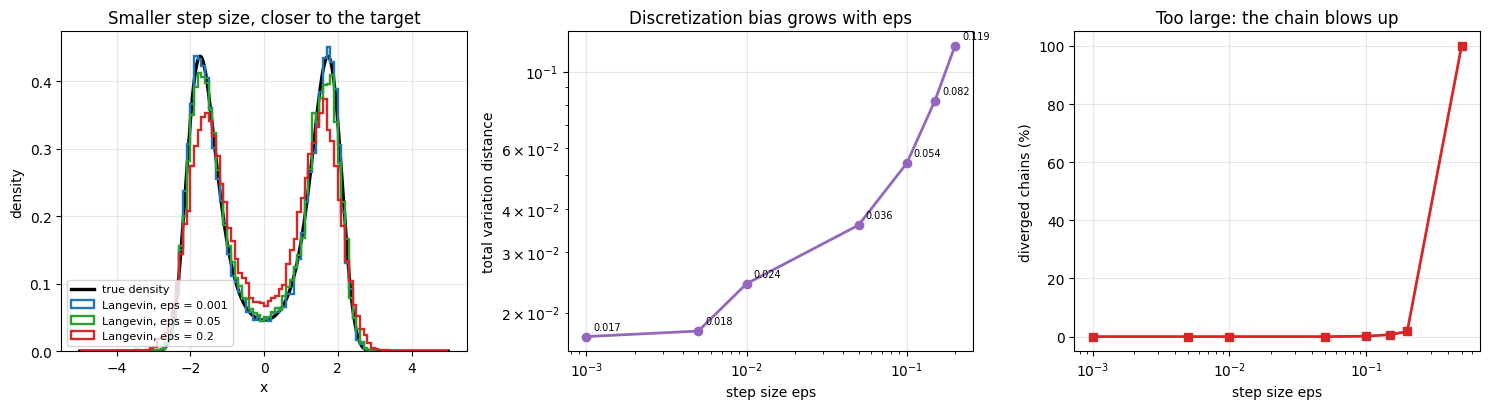

In [4]:
# ============================================================
# 図: ステップサイズの効果
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

mask_p = (xs >= -5) & (xs <= 5)
axes[0].plot(xs[mask_p], p_true[mask_p], lw=2.4, color="k", label="true density")
for eps, color in [(0.001, "tab:blue"), (0.05, "tab:green"), (0.2, "tab:red")]:
    s = samples_by_eps[eps]
    s = s[torch.isfinite(s)]
    axes[0].hist(s.numpy(), bins=100, range=(-5, 5), density=True,
                 histtype="step", lw=1.7, color=color, label=f"Langevin, eps = {eps}")
axes[0].set_xlabel("x")
axes[0].set_ylabel("density")
axes[0].set_title("Smaller step size, closer to the target")
axes[0].legend(fontsize=8)

es = [r[0] for r in eps_rows]
axes[1].loglog(es, [r[3] for r in eps_rows], "o-", lw=2, color="tab:purple")
axes[1].set_xlabel("step size eps")
axes[1].set_ylabel("total variation distance")
axes[1].set_title("Discretization bias grows with eps")
for r in eps_rows:
    if np.isfinite(r[3]):
        axes[1].annotate(f"{r[3]:.3f}", (r[0], r[3]), textcoords="offset points",
                         xytext=(5, 5), fontsize=7)

axes[2].semilogx(es, [r[1] * 100 for r in eps_rows], "s-", lw=2, color="tab:red")
axes[2].set_xlabel("step size eps")
axes[2].set_ylabel("diverged chains (%)")
axes[2].set_title("Too large: the chain blows up")
axes[2].set_ylim(-5, 105)

plt.tight_layout()
plt.show()

### 読み取れること — $\epsilon$ には上下から挟まれた窓がある

| $\epsilon$ | 全変動距離 | 発散した割合 |
|---|---|---|
| 0.001 | 0.0171 | 0.00% |
| 0.01 | 0.0243 | 0.00% |
| 0.05 | 0.0359 | 0.00% |
| 0.1 | 0.0542 | 0.12% |
| 0.2 | 0.1188 | 1.75% |
| 0.5 | — | **100%** |

- **小さすぎると**: 正確だが1ステップで動く距離が小さく、収束に膨大なステップが必要。
  （本節は 3000 ステップ固定なので、$\epsilon = 0.001$ でも全変動 0.017 残っています）
- **大きすぎると**: 離散化の誤差が入って**別の分布**になり、さらに大きくすると**発散**します。

発散の機構はエネルギーの形にあります。$E = \frac{1}{4}x^4 - \frac{3}{2}x^2$ の勾配は
$x^3 - 3x$ で、$|x|$ が大きいと3次で増大します。$\epsilon$ が大きいと
$x \to x - \frac{\epsilon}{2}(x^3 - 3x)$ が行き過ぎて反対側のさらに遠くへ飛び、
次のステップでもっと遠くへ飛ぶ、という正のフィードバックが起きます。

> ⚠️ **実務上の含意**: EBM の学習中はエネルギーの形が**毎ステップ変わります**。
> 学習が進んでエネルギーが鋭くなると、同じ $\epsilon$ が突然大きすぎになります。
> 「最初は動いていたのに途中で NaN になる」の典型的な原因です。
> 第5節ではこれが実際に起きます。

<a id="noise"></a>
## 3. ノイズのスケールを間違えると別の分布になる

更新式の係数 $\frac{\epsilon}{2}$（ドリフト）と $\sqrt{\epsilon}$（ノイズ）は
つり合いのために決まっています。片方を変えると**別の分布の定常状態**になります。

4通り試します。

| 設定 | 予想される結果 |
|---|---|
| $\sqrt{\epsilon}$（正しい） | $p$ に収束 |
| $\epsilon$（小さすぎ） | ノイズが効かず最適化寄りになる |
| $0$（ノイズ無し） | **勾配降下**。エネルギーの極小に全部集まる |
| $2\sqrt{\epsilon}$（大きすぎ） | 広がりすぎる = 温度が高い分布 |

ノイズ無しの場合の予想は具体的に書けます。$E$ の極小は $x = \pm\sqrt{3}$ なので、
全サンプルがそこに集まり、**標準偏差は $\sqrt{3} = 1.7321$** になるはずです
（左右に半分ずつ、平均 0 なので）。

In [5]:
# ============================================================
# ノイズ係数を変える
# ============================================================

EPS_FIX = 0.01
noise_variants = [
    ("sqrt(eps) : correct", math.sqrt(EPS_FIX)),
    ("eps : too small", EPS_FIX),
    ("0 : no noise", 0.0),
    ("2*sqrt(eps) : too large", 2 * math.sqrt(EPS_FIX)),
]

noise_rows = []
samples_by_noise = {}
for name, coef in noise_variants:
    s = langevin_1d(x0, EPS_FIX, 3000, noise_coef=coef, seed=1)
    sd = float(s.std())
    tv = total_variation(s)
    noise_rows.append((name, coef, sd, tv))
    samples_by_noise[name] = s
    print(f"{name:24s} (係数 {coef:.4f}): 標準偏差 {sd:.4f}   全変動距離 {tv:.4f}")

print()
print(f"真値              : 標準偏差 {true_sd:.4f}")
print(f"エネルギー極小 sqrt(3) = {math.sqrt(3):.4f}  <- ノイズ無しの予想値")
print()
sd_nonoise = [r[2] for r in noise_rows if "no noise" in r[0]][0]
print(f"ノイズ無しの実測標準偏差 {sd_nonoise:.4f} vs 予想 sqrt(3) = {math.sqrt(3):.4f}  "
      f"差 {abs(sd_nonoise - math.sqrt(3)):.4f}")

sqrt(eps) : correct      (係数 0.1000): 標準偏差 1.6102   全変動距離 0.0243


eps : too small          (係数 0.0100): 標準偏差 1.7310   全変動距離 0.7822


0 : no noise             (係数 0.0000): 標準偏差 1.7320   全変動距離 0.9126


2*sqrt(eps) : too large  (係数 0.2000): 標準偏差 1.6091   全変動距離 0.2651

真値              : 標準偏差 1.6079
エネルギー極小 sqrt(3) = 1.7321  <- ノイズ無しの予想値

ノイズ無しの実測標準偏差 1.7320 vs 予想 sqrt(3) = 1.7321  差 0.0001


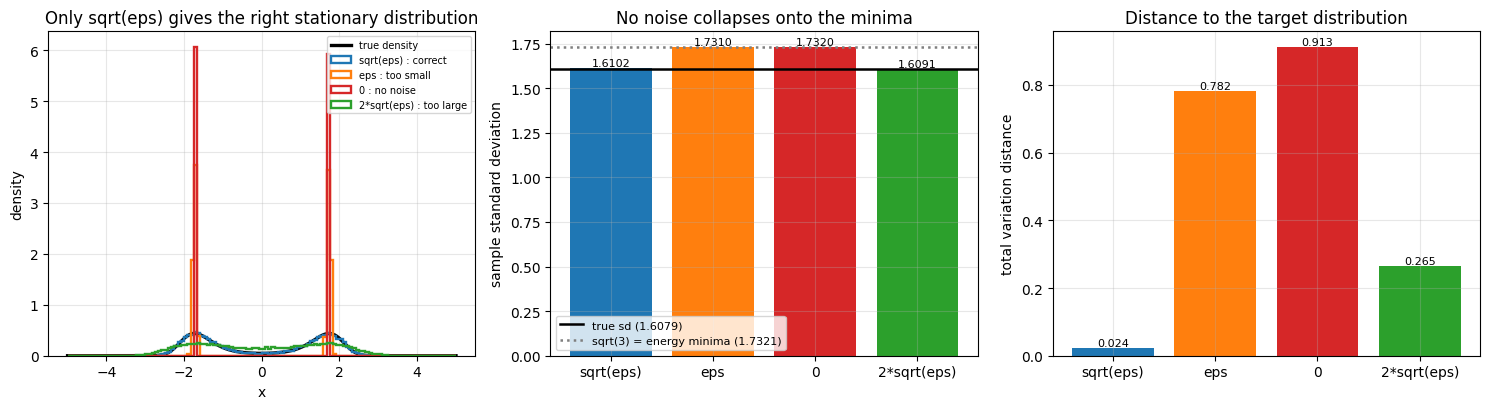

In [6]:
# ============================================================
# 図: ノイズ係数の効果
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(xs[mask_p], p_true[mask_p], lw=2.4, color="k", label="true density")
for (name, _), color in zip(noise_variants,
                            ["tab:blue", "tab:orange", "tab:red", "tab:green"]):
    s = samples_by_noise[name]
    axes[0].hist(s.numpy(), bins=120, range=(-5, 5), density=True,
                 histtype="step", lw=1.7, color=color, label=name)
axes[0].set_xlabel("x")
axes[0].set_ylabel("density")
axes[0].set_title("Only sqrt(eps) gives the right stationary distribution")
axes[0].legend(fontsize=7)

names_short = ["sqrt(eps)", "eps", "0", "2*sqrt(eps)"]
axes[1].bar(names_short, [r[2] for r in noise_rows],
            color=["tab:blue", "tab:orange", "tab:red", "tab:green"])
axes[1].axhline(true_sd, color="k", ls="-", lw=1.8, label=f"true sd ({true_sd:.4f})")
axes[1].axhline(math.sqrt(3), color="tab:gray", ls=":", lw=1.8,
                label=f"sqrt(3) = energy minima ({math.sqrt(3):.4f})")
axes[1].set_ylabel("sample standard deviation")
axes[1].set_title("No noise collapses onto the minima")
axes[1].legend(fontsize=8)
for i, r in enumerate(noise_rows):
    axes[1].text(i, r[2], f"{r[2]:.4f}", ha="center", va="bottom", fontsize=8)

axes[2].bar(names_short, [r[3] for r in noise_rows],
            color=["tab:blue", "tab:orange", "tab:red", "tab:green"])
axes[2].set_ylabel("total variation distance")
axes[2].set_title("Distance to the target distribution")
for i, r in enumerate(noise_rows):
    axes[2].text(i, r[3], f"{r[3]:.3f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — ノイズ無しは「最適化」になる

| 設定 | 標準偏差 | 全変動距離 |
|---|---|---|
| $\sqrt{\epsilon}$（正しい） | 1.6102 | **0.0243** |
| $\epsilon$（小さすぎ） | 1.7310 | 0.7822 |
| $0$（ノイズ無し） | **1.7320** | **0.9126** |
| $2\sqrt{\epsilon}$（大きすぎ） | 1.6091 | 0.2651 |

**ノイズ無しの標準偏差 1.7320 は $\sqrt{3} = 1.7321$ とほぼ完全に一致しました。**
予想どおり、全サンプルがエネルギーの極小 $x = \pm\sqrt{3}$ に集まっています。
これは**分布ではなく2点の集まり**で、全変動距離 0.9126（最大 1）は
「ほとんど別物」という値です。

注目すべきは $\epsilon$（小さすぎ）が**ノイズ無しとほぼ同じ**になっていることです
（1.7310 vs 1.7320）。$\epsilon = 0.01$ なら $\sqrt{\epsilon} = 0.1$ に対して
$\epsilon = 0.01$ は 10 分の 1 で、この分布のスケールでは「無いのと同じ」でした。

逆に $2\sqrt{\epsilon}$（大きすぎ）は標準偏差が 1.6091 で真値 1.6079 に**近い**のに、
全変動距離は 0.2651 と悪いです。**モーメントが合っていても分布が合っているとは
限らない**という、サンプラーの診断で最も重要な注意点です。

> 📌 **ここが 195 への伏線です。** ノイズの大きさは「温度」に対応します。
> $\sqrt{2T\epsilon}$ にすると $p^{1/T}$ からサンプルすることになります。
> **ノイズの量を時間とともに変える**という発想を進めると拡散モデルになります。
> 本章の第4節で焼きなましとして使い、195 で統合します。

<a id="mixing"></a>
## 4. モード間の混合 — 集計統計に騙される

ランジュバンの最大の弱点は**分離したモード間を渡れない**ことです。
モードの間は確率が低く、そこへ向かうスコアは「戻れ」という向きを指します。
渡るにはノイズだけで谷を越える必要があり、その確率は指数的に小さいです。

2次元の 4 峰混合ガウス（中心が $(\pm 3, \pm 3)$、$\sigma = 0.5$）で測ります。
モードの間隔は 6、標準偏差は 0.5 なので **12 シグマ離れています**。

### 測る量を2つ用意する

ここが本節の要点です。**集計統計だけ見ると混合していないことに気づけません。**

| 指標 | 測るもの | 騙されるか |
|---|---|---|
| 最終的なモード占有率 | 全チェーンを合わせた分布 | **騙される**（初期値が対称なら正しく見える） |
| 1チェーンが訪れたモード数 | 個々のチェーンの混合 | 騙されない |

初期値を2通り用意して確かめます。

In [7]:
# ============================================================
# 2次元・4峰混合ガウス（12シグマ離れている）
# ============================================================

MODES = torch.tensor([[-3.0, -3.0], [3.0, 3.0], [-3.0, 3.0], [3.0, -3.0]])
MODE_SD = 0.5
print(f"モード間隔 {float((MODES[0]-MODES[2]).norm()):.1f} / 標準偏差 {MODE_SD} "
      f"= {float((MODES[0]-MODES[2]).norm())/MODE_SD:.0f} シグマ")

def log_p_2d(x):
    d2 = ((x[:, None, :] - MODES[None]) ** 2).sum(-1)
    comp = -0.5 * d2 / MODE_SD**2 - math.log(2 * math.pi * MODE_SD**2)
    return torch.logsumexp(comp, -1) + math.log(0.25)

def score_2d(x):
    # 解析的なスコア: responsibility で重み付けした (mu_k - x)/sd^2 の和
    d2 = ((x[:, None, :] - MODES[None]) ** 2).sum(-1)
    comp = -0.5 * d2 / MODE_SD**2 - math.log(2 * math.pi * MODE_SD**2)
    r = torch.softmax(comp, dim=-1)                      # responsibility
    return ((MODES[None] - x[:, None, :]) / MODE_SD**2 * r[..., None]).sum(1)

# autograd と一致するか確認
xt = torch.randn(5, 2, requires_grad=True)
log_p_2d(xt).sum().backward()
print(f"解析スコアと autograd の最大差: "
      f"{float((score_2d(xt.detach()) - xt.grad).abs().max()):.2e}")

def nearest_mode(x):
    return ((x[:, None, :] - MODES[None]) ** 2).sum(-1).argmin(-1)

def langevin_2d(x0, eps, steps, temps=None, seed=0, record_every=10):
    gen = torch.Generator().manual_seed(seed)
    x = x0.clone()
    visits = []
    for t in range(steps):
        T = 1.0 if temps is None else temps[t]
        # 温度 T の分布 p^(1/T) を狙う: スコアを 1/T 倍する
        x = (x + 0.5 * eps * score_2d(x) / T
             + math.sqrt(eps) * torch.randn(x.shape, generator=gen))
        if t % record_every == 0:
            visits.append(nearest_mode(x))
    return x, torch.stack(visits)

def mixing_report(x, visits, n):
    n_visited = torch.tensor([torch.unique(visits[:, i]).numel()
                              for i in range(n)]).float()
    occ = torch.bincount(nearest_mode(x), minlength=4).float() / n
    return float(n_visited.mean()), occ, float((occ - 0.25).abs().max())

モード間隔 6.0 / 標準偏差 0.5 = 12 シグマ
解析スコアと autograd の最大差: 1.43e-05


In [8]:
# ============================================================
# 初期値を対称 / 非対称にして比べる
# ============================================================

N_CHAIN = 2000
STEPS = 2000
EPS_2D = 0.05

torch.manual_seed(5)
x0_symmetric = torch.randn(N_CHAIN, 2) * 0.5          # 原点付近（4モードに対して対称）
x0_one_mode = MODES[0] + torch.randn(N_CHAIN, 2) * 0.3  # 全部モード0から出発

mix_rows = []
final_2d = {}
for tag, x_init in [("symmetric init (near origin)", x0_symmetric),
                    ("asymmetric init (all at mode 0)", x0_one_mode)]:
    x, vis = langevin_2d(x_init, EPS_2D, STEPS, seed=2)
    visited, occ, maxdev = mixing_report(x, vis, N_CHAIN)
    mix_rows.append((tag, visited, occ.numpy(), maxdev))
    final_2d[tag] = x
    print(f"{tag}")
    print(f"  1チェーンが訪れたモード数 平均 {visited:.2f} / 4")
    print(f"  最終モード占有率 {occ.numpy().round(3)}  （真は各 0.25）")
    print(f"  占有率の最大偏差 {maxdev:.3f}")
    print()

print(f"-> 対称な初期値では占有率がほぼ完璧（最大偏差 {mix_rows[0][3]:.3f}）に見えるが、")
print(f"   1チェーンは平均 {mix_rows[0][1]:.2f} モードしか訪れていない。混合していない。")
print("   初期値の対称性が偶然救っているだけで、サンプラーは壊れている。")
print(f"   非対称な初期値にすると占有率 {mix_rows[1][2].round(2)} で一目で分かる"
      f"（最大偏差 {mix_rows[1][3]:.3f}）。")

symmetric init (near origin)
  1チェーンが訪れたモード数 平均 1.03 / 4
  最終モード占有率 [0.245 0.262 0.243 0.25 ]  （真は各 0.25）
  占有率の最大偏差 0.012



asymmetric init (all at mode 0)
  1チェーンが訪れたモード数 平均 1.00 / 4
  最終モード占有率 [1. 0. 0. 0.]  （真は各 0.25）
  占有率の最大偏差 0.750

-> 対称な初期値では占有率がほぼ完璧（最大偏差 0.012）に見えるが、
   1チェーンは平均 1.03 モードしか訪れていない。混合していない。
   初期値の対称性が偶然救っているだけで、サンプラーは壊れている。
   非対称な初期値にすると占有率 [1. 0. 0. 0.] で一目で分かる（最大偏差 0.750）。


In [9]:
# ============================================================
# 焼きなまし: 温度を下げながら動かす
# ============================================================

anneal_rows = []
t0 = time.time()
for steps in [2000, 6000, 12000]:
    temps = torch.exp(torch.linspace(math.log(40.0), math.log(1.0), steps)).tolist()
    x, vis = langevin_2d(x0_one_mode, EPS_2D, steps, temps=temps, seed=2)
    visited, occ, maxdev = mixing_report(x, vis, N_CHAIN)
    anneal_rows.append((steps, visited, occ.numpy(), maxdev))
    final_2d[f"annealed {steps} steps"] = x
    print(f"焼きなまし T: 40 -> 1 を {steps:6,} ステップ: "
          f"訪問モード数 {visited:.2f}/4  占有率 {occ.numpy().round(3)}  "
          f"最大偏差 {maxdev:.3f}")
print(f"\n計算時間 {time.time() - t0:.1f}s")
print()
print("-> 焼きなましは効くが、十分な長さが必要。")
print(f"   2,000 ステップでは最大偏差 {anneal_rows[0][3]:.3f}（まだ偏っている）、")
print(f"   6,000 ステップで {anneal_rows[1][3]:.3f} まで下がる。")
print("   「温度を下げれば解決」ではなく「3倍の計算を払えば解決」が正しい。")

焼きなまし T: 40 -> 1 を  2,000 ステップ: 訪問モード数 2.50/4  占有率 [0.373 0.148 0.234 0.245]  最大偏差 0.123


焼きなまし T: 40 -> 1 を  6,000 ステップ: 訪問モード数 3.54/4  占有率 [0.268 0.241 0.236 0.254]  最大偏差 0.018


焼きなまし T: 40 -> 1 を 12,000 ステップ: 訪問モード数 3.92/4  占有率 [0.245 0.235 0.25  0.27 ]  最大偏差 0.021

計算時間 4.9s

-> 焼きなましは効くが、十分な長さが必要。
   2,000 ステップでは最大偏差 0.123（まだ偏っている）、
   6,000 ステップで 0.018 まで下がる。
   「温度を下げれば解決」ではなく「3倍の計算を払えば解決」が正しい。


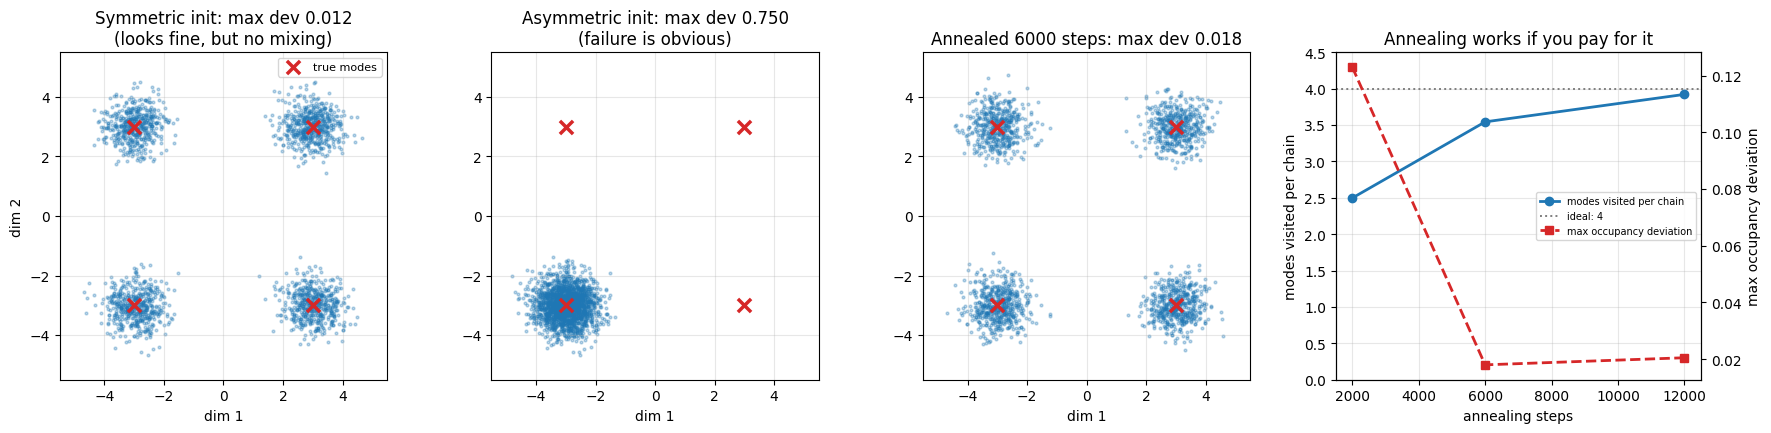

In [10]:
# ============================================================
# 図: モード間の混合
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))

def scatter_modes(ax, x, title):
    xn = x.numpy()
    ax.scatter(xn[:, 0], xn[:, 1], s=4, alpha=0.3, color="tab:blue")
    ax.scatter(MODES[:, 0], MODES[:, 1], s=90, marker="x", color="tab:red",
               lw=2.5, label="true modes")
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-5.5, 5.5)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("dim 1")

scatter_modes(axes[0], final_2d["symmetric init (near origin)"],
              f"Symmetric init: max dev {mix_rows[0][3]:.3f}\n(looks fine, but no mixing)")
axes[0].set_ylabel("dim 2")
axes[0].legend(fontsize=8)
scatter_modes(axes[1], final_2d["asymmetric init (all at mode 0)"],
              f"Asymmetric init: max dev {mix_rows[1][3]:.3f}\n(failure is obvious)")
scatter_modes(axes[2], final_2d["annealed 6000 steps"],
              f"Annealed 6000 steps: max dev {anneal_rows[1][3]:.3f}")

steps_a = [r[0] for r in anneal_rows]
ax = axes[3]
ax.plot(steps_a, [r[1] for r in anneal_rows], "o-", lw=2, color="tab:blue",
        label="modes visited per chain")
ax.axhline(4.0, color="tab:gray", ls=":", lw=1.4, label="ideal: 4")
ax.set_xlabel("annealing steps")
ax.set_ylabel("modes visited per chain")
ax.set_ylim(0, 4.5)
ax2 = ax.twinx()
ax2.plot(steps_a, [r[3] for r in anneal_rows], "s--", lw=2, color="tab:red",
         label="max occupancy deviation")
ax2.set_ylabel("max occupancy deviation")
ax2.grid(False)
ax.set_title("Annealing works if you pay for it")
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], fontsize=7, loc="center right")

plt.tight_layout()
plt.show()

### 読み取れること — 診断には個別チェーンの指標が必要

| 設定 | 訪問モード数 | 占有率 | 最大偏差 |
|---|---|---|---|
| 対称な初期値 | **1.03 / 4** | [0.245, 0.262, 0.243, 0.250] | **0.012** |
| 非対称な初期値 | 1.00 / 4 | [1.000, 0.000, 0.000, 0.000] | 0.750 |
| 焼きなまし 2,000 step | 2.50 / 4 | [0.373, 0.148, 0.234, 0.245] | 0.123 |
| 焼きなまし 6,000 step | 3.54 / 4 | [0.268, 0.241, 0.236, 0.254] | 0.018 |
| 焼きなまし 12,000 step | 3.92 / 4 | [0.245, 0.235, 0.250, 0.270] | 0.021 |

**1行目が本節の主題です。** 占有率の最大偏差 0.012 は「完璧」に見えます
（真の 0.25 に対して 5% の誤差で、サンプル数 2,000 の統計誤差の範囲内です）。
論文や報告でこの数字だけ見せられたら、サンプラーが正しく動いていると判断するでしょう。
しかし**1チェーンが訪れたモードは平均 1.03** — ほとんどのチェーンは
最初に落ちたモードから一度も出ていません。

なぜ占有率が合ったかというと、**初期値が 4 モードに対して対称だった**からです。
原点付近から出発したチェーンは最も近いモードに落ち、対称性からそれが
ほぼ均等に分かれます。**サンプラーの性能ではなく初期値の性質**が数字を作っていました。

初期値を1モードに寄せると占有率が [1, 0, 0, 0] になり、一目で壊れていると分かります。
**非対称な初期値から始めるのが、混合の最も安い検査**です。

焼きなましは効きますが**代償が明確**です。2,000 ステップでは最大偏差 0.123 で
まだ偏っており（占有率 [0.373, 0.148, ...] で2つのモードが 2.5 倍違う）、
0.02 まで下げるには 6,000 ステップ（3倍）必要でした。
「温度を下げれば解決する」ではなく「**3倍の計算を払えば解決する**」が正しい表現です。

> 💡 **なぜ焼きなましが効くのか**: 高温では $p^{1/T}$ が平坦になり、モード間の谷が浅くなります。
> 谷を越えてから温度を下げれば、どのモードにも行ける状態から収束できます。
> **「ノイズの大きい状態から始めて徐々に下げる」** — これは拡散モデルの逆過程と
> 同じ構造です。195 で両者が同じものだと分かります。

<a id="cd"></a>
## 5. ランジュバンで EBM を学習する（CD）

193 で導いた最尤の勾配を思い出します。

$$\nabla_\theta \big(-\log p_\theta(x)\big)
= \nabla_\theta E_\theta(x_{\text{data}})
- \mathbb{E}_{x' \sim p_\theta}\big[\nabla_\theta E_\theta(x')\big]$$

第2項の $x' \sim p_\theta$ を**ランジュバンで作ります**。これが
**コントラスティブ・ダイバージェンス（CD）** です。

実装は驚くほど単純で、損失をこう書くだけです。

```python
loss = E(x_data).mean() - E(x_negative).mean()
```

$x_{\text{negative}}$ は $k$ ステップのランジュバンで作ります。これを **CD-$k$** と呼びます。

### 本節の設計 — 近似で学習し、厳密に評価する

$k$ を小さくすると $x_{\text{negative}}$ は $p_\theta$ から遠くなります。
193 の Q4 で立てた予想は「**サンプラーの質が悪いと崩壊する**」でした。

これを**定量化**するために、2次元を使います。

- **学習**は CD（近似的な負のサンプル）で行う
- **評価**は格子で $\log Z$ を厳密に計算して行う（193 第6節と同じ）

こうすると「サンプラーの質が最終的な尤度をどれだけ損なうか」が**nats で測れます**。
基準は 193 の厳密最尤 **2.8309**（下限 2.8275）です。

4つ試します。

| 手法 | 負のサンプルの作り方 |
|---|---|
| CD-1 | 毎回ノイズから 1 ステップだけ |
| CD-10 / CD-50 | 毎回ノイズから 10 / 50 ステップ |
| PCD-10 | **永続チェーン**。バッファから取り出して 10 ステップ進め、戻す（5% はランダムに再初期化） |
| CD-1 + 正則化 | CD-1 に $\lambda(E(x)^2)$ の罰則を足してエネルギーの暴走を抑える |

In [11]:
# ============================================================
# 目標分布（193 と同一）と厳密評価用の格子
# ============================================================

MUS4 = np.array([[-2.0, -2.0], [2.0, 2.0], [-2.0, 2.0], [2.0, -2.0]])
SD4 = 0.5

def sample_gmm4(n, seed=0):
    r = np.random.default_rng(seed)
    k = r.integers(0, 4, n)
    return (MUS4[k] + r.standard_normal((n, 2)) * SD4).astype(np.float32)

def logsumexp_np(a, axis):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def gmm4_logpdf(x):
    comps = [-0.5 * ((x - m) ** 2).sum(-1) / SD4**2 - np.log(2 * np.pi * SD4**2)
             for m in MUS4]
    return logsumexp_np(np.stack(comps, -1), axis=-1) + np.log(0.25)

X4_train = sample_gmm4(8000, seed=0)
X4_test = sample_gmm4(4000, seed=1)
NLL_LB = float(-gmm4_logpdf(X4_test).mean())

K4 = 128
g4 = torch.linspace(-5, 5, K4)
CELL4 = float(10.0 / (K4 - 1)) ** 2
G4X, G4Y = torch.meshgrid(g4, g4, indexing="ij")
GRID4 = torch.stack([G4X.reshape(-1), G4Y.reshape(-1)], -1)

print(f"下限 {NLL_LB:.4f}  /  193 の厳密最尤 2.8309（参照値）")
print(f"評価用の格子 {K4}x{K4} = {GRID4.shape[0]:,} 点")


class EnergyNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def log_partition4(E_net):
    return torch.logsumexp(-E_net(GRID4), 0) + math.log(CELL4)


def langevin_negatives(E_net, x, k, eps=0.05):
    # 学習中のエネルギーに対するランジュバン。スコアは -grad E
    for _ in range(k):
        x = x.detach().requires_grad_(True)
        grad_E = torch.autograd.grad(E_net(x).sum(), x)[0]
        x = (x - 0.5 * eps * grad_E + math.sqrt(eps) * torch.randn_like(x)).detach()
    return x

下限 2.8275  /  193 の厳密最尤 2.8309（参照値）
評価用の格子 128x128 = 16,384 点


In [12]:
# ============================================================
# CD / PCD で学習し、厳密な log Z で評価する
# ============================================================

def train_cd(k, persistent=False, reg=0.0, steps_total=1500, batch=512,
             buf_size=4096, reinit_frac=0.05, lr=2e-3, seed=1):
    torch.manual_seed(seed)
    E_net = EnergyNet()
    opt = torch.optim.Adam(E_net.parameters(), lr=lr)
    X = torch.tensor(X4_train)
    buffer = torch.randn(buf_size, 2) * 2.0
    diverged_at = None
    t0 = time.time()
    for step in range(steps_total):
        xb = X[torch.randint(0, len(X), (batch,))]
        if persistent:
            idx = torch.randint(0, buf_size, (batch,))
            x_init = buffer[idx].clone()
            m = torch.rand(batch) < reinit_frac       # 一部をランダムに再初期化
            x_init[m] = torch.randn(int(m.sum()), 2) * 2.0
        else:
            x_init = torch.randn(batch, 2) * 2.0
        x_neg = langevin_negatives(E_net, x_init, k)
        if persistent:
            buffer[idx] = x_neg.detach()
        loss = E_net(xb).mean() - E_net(x_neg).mean()
        if reg > 0:
            loss = loss + reg * (E_net(xb).pow(2).mean() + E_net(x_neg).pow(2).mean())
        opt.zero_grad()
        loss.backward()
        opt.step()
        if diverged_at is None and not torch.isfinite(loss):
            diverged_at = step
    with torch.no_grad():
        test_nll = float(E_net(torch.tensor(X4_test)).mean() + log_partition4(E_net))
        dens = torch.exp(-E_net(GRID4) - log_partition4(E_net))
    return {"nll": test_nll, "time": time.time() - t0, "diverged": diverged_at,
            "dens": dens.numpy().reshape(K4, K4), "net": E_net}

cd_configs = [
    ("CD-1", dict(k=1)),
    ("CD-10", dict(k=10)),
    ("CD-50", dict(k=50)),
    ("PCD-10 (buffer + 5% reinit)", dict(k=10, persistent=True)),
    ("CD-1 + energy regularization", dict(k=1, reg=0.1)),
]

cd_results = []
for tag, kw in cd_configs:
    res = train_cd(**kw)
    cd_results.append((tag, res))
    gap = res["nll"] - NLL_LB
    print(f"{tag:30s}: test NLL {res['nll']:16.4f}  "
          f"（下限まで {gap:+.4f}）  {res['time']:.0f}s")

print()
print(f"参照: 193 の厳密最尤（格子で log Z を計算）  2.8309  （下限まで +0.0033）")
print(f"参照: 到達可能な下限                        {NLL_LB:.4f}")

CD-1                          : test NLL  4406944256.0000  （下限まで +4406944253.1725）  3s


CD-10                         : test NLL           3.3307  （下限まで +0.5032）  11s


CD-50                         : test NLL           2.8606  （下限まで +0.0330）  46s


PCD-10 (buffer + 5% reinit)   : test NLL           3.2617  （下限まで +0.4342）  11s


CD-1 + energy regularization  : test NLL           3.1240  （下限まで +0.2964）  5s

参照: 193 の厳密最尤（格子で log Z を計算）  2.8309  （下限まで +0.0033）
参照: 到達可能な下限                        2.8275


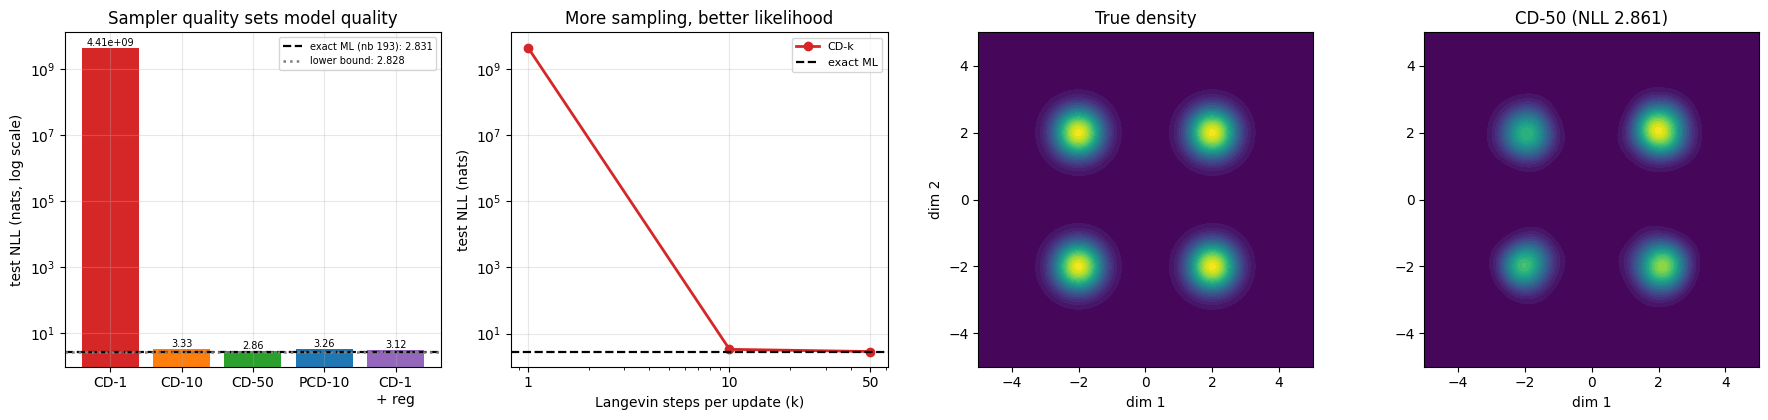

In [13]:
# ============================================================
# 図: サンプラーの質と学習結果
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))

tags = [t for t, _ in cd_results]
nlls = [r["nll"] for _, r in cd_results]
short = ["CD-1", "CD-10", "CD-50", "PCD-10", "CD-1\n+ reg"]
colors = ["tab:red", "tab:orange", "tab:green", "tab:blue", "tab:purple"]
axes[0].bar(short, nlls, color=colors)
axes[0].axhline(2.8309, color="k", ls="--", lw=1.6, label="exact ML (nb 193): 2.831")
axes[0].axhline(NLL_LB, color="tab:gray", ls=":", lw=1.8,
                label=f"lower bound: {NLL_LB:.3f}")
axes[0].set_yscale("log")
axes[0].set_ylabel("test NLL (nats, log scale)")
axes[0].set_title("Sampler quality sets model quality")
axes[0].legend(fontsize=7)
for i, v in enumerate(nlls):
    axes[0].text(i, v, f"{v:.3g}", ha="center", va="bottom", fontsize=7)

ks = [1, 10, 50]
ks_nll = [cd_results[0][1]["nll"], cd_results[1][1]["nll"], cd_results[2][1]["nll"]]
axes[1].loglog(ks, ks_nll, "o-", lw=2, color="tab:red", label="CD-k")
axes[1].axhline(2.8309, color="k", ls="--", lw=1.6, label="exact ML")
axes[1].set_xlabel("Langevin steps per update (k)")
axes[1].set_ylabel("test NLL (nats)")
axes[1].set_title("More sampling, better likelihood")
axes[1].set_xticks(ks)
axes[1].set_xticklabels(ks)
axes[1].legend(fontsize=8)

dens_true4 = np.exp(gmm4_logpdf(np.stack([G4X.numpy(), G4Y.numpy()], -1)))
axes[2].contourf(G4X.numpy(), G4Y.numpy(), dens_true4, levels=30, cmap="viridis")
axes[2].set_aspect("equal")
axes[2].set_title("True density")
axes[2].set_xlabel("dim 1")
axes[2].set_ylabel("dim 2")
axes[2].grid(False)

best = min(cd_results[1:], key=lambda r: r[1]["nll"])
axes[3].contourf(G4X.numpy(), G4Y.numpy(), best[1]["dens"], levels=30, cmap="viridis")
axes[3].set_aspect("equal")
axes[3].set_title(f"{best[0]} (NLL {best[1]['nll']:.3f})")
axes[3].set_xlabel("dim 1")
axes[3].grid(False)

plt.tight_layout()
plt.show()

### 読み取れること — 193 の予想は当たった

| 手法 | test NLL | 下限までの差 | 計算時間 |
|---|---|---|---|
| **CD-1** | **4.4 × 10⁹** | 崩壊 | 3s |
| CD-10 | 3.3307 | +0.5032 | 11s |
| CD-50 | 2.8606 | +0.0330 | 46s |
| PCD-10（バッファ + 5% 再初期化） | 3.2617 | +0.4342 | 11s |
| CD-1 + エネルギー正則化 | 3.1240 | +0.2964 | 5s |
| **厳密最尤（193、$Z$ を格子で計算）** | **2.8309** | **+0.0034** | 17s |
| 到達可能な下限 | 2.8275 | 0 | — |

**CD-1 は $4.4 \times 10^9$ まで吹き飛びました。** 193 の Q4 で予想した
「サンプラーが届かない場所のエネルギーが下がり放題になる」が、まさに起きています。
1 ステップでは負のサンプルが初期ノイズの近くにしか行かず、
データ付近とそこ以外のエネルギーを押し上げ/押し下げる力がつり合いません。

**$k$ を増やすと単調に改善します**（$4.4\times10^9 \to 3.33 \to 2.86$）。
CD-50 は厳密最尤 2.8309 まで残り 0.03 nats で、**近似サンプリングでここまで来ます**。
ただし計算時間は 3s → 46s と **15 倍**です。
サンプラーの質は**そのまま計算コスト**です。

**PCD-10 は CD-10 をわずかに上回りました**（3.2617 vs 3.3307）が、
期待したほどの差ではありません。永続チェーンの利点（チェーンが
エネルギーの変化に追従して長い実効チェーン長を得る）は、
この設定（学習率 2e-3、1500 ステップ）では十分に出ませんでした。
**これは「PCD が CD より良い」という一般論を本章の実測が支持しないという意味**であり、
設定依存だと理解すべきです（単一設定・単一シードの結果です）。

**CD-1 + エネルギー正則化が最も情報量のある結果です。** $\lambda \cdot E(x)^2$ を
足すだけで $4.4\times10^9$ から **3.1240** まで戻りました。
正則化は負のサンプルの質を改善しません。**エネルギーが暴走する自由を奪っている**だけです。
つまり

> **サンプラーが弱いとき、正則化がその穴を部分的に埋める。**

これは実装上きわめて重要です。EBM の実装が「動く」のは、
多くの場合サンプラーが良いからではなく**正則化とスペクトル制約が効いているから**です。

<a id="summary"></a>
## 6. まとめとチートシート

### ランジュバン動力学

$$x_{t+1} = x_t + \frac{\epsilon}{2}\nabla_x \log p(x_t) + \sqrt{\epsilon}\,\eta_t,
\qquad \nabla_x \log p = -\nabla_x E$$

| 変更 | 結果（本章の実測、1次元二重井戸） |
|---|---|
| 正しい $\sqrt{\epsilon}$ | 全変動距離 0.0243 |
| ノイズを $\epsilon$ に（小さすぎ） | 0.7822（ほぼ最適化と同じ） |
| ノイズを $0$ に | 0.9126。標準偏差 1.7320 = $\sqrt{3}$（極小に潰れる） |
| ノイズを $2\sqrt{\epsilon}$ に | 0.2651（標準偏差は合うのに分布は違う） |

### ステップサイズ $\epsilon$ の窓

| $\epsilon$ | 全変動距離 | 発散 |
|---|---|---|
| 0.001 | 0.0171 | 0% |
| 0.05 | 0.0359 | 0% |
| 0.2 | 0.1188 | 1.75% |
| 0.5 | — | 100% |

下は収束の遅さ、上は離散化誤差と発散で挟まれます。
しかも EBM の学習中は**エネルギーの形が毎ステップ変わる**ので、
安全な $\epsilon$ も動きます。

### 混合の診断（本章で最重要）

| 指標 | 対称な初期値 | 非対称な初期値 |
|---|---|---|
| 占有率の最大偏差 | **0.012（統計誤差の範囲=完璧に見える）** | 0.750 |
| 1チェーンの訪問モード数 | **1.03 / 4** | 1.00 / 4 |

**集計統計は初期値の対称性で簡単に嘘をつきます。**
検査は (a) **非対称な初期値から始める**、(b) **個別チェーンの訪問モード数を測る**、
の2つを必ず入れること。

焼きなまし（$T: 40 \to 1$）は効きますが代償があります。

| ステップ数 | 訪問モード数 | 占有率の最大偏差 |
|---|---|---|
| 2,000 | 2.50 / 4 | 0.123 |
| 6,000 | 3.54 / 4 | 0.018 |
| 12,000 | 3.92 / 4 | 0.021 |

### CD による学習（2次元、評価は厳密な $Z$）

| 手法 | test NLL | 下限までの差 |
|---|---|---|
| CD-1 | $4.4\times10^9$ | 崩壊 |
| CD-10 | 3.3307 | +0.5032 |
| CD-50 | 2.8606 | +0.0330 |
| PCD-10 | 3.2617 | +0.4342 |
| CD-1 + 正則化 | 3.1240 | +0.2964 |
| 厳密最尤（193） | 2.8309 | +0.0034 |

**サンプラーの質がそのまま尤度になる。** そして正則化が穴を部分的に埋める。

### 195 への橋

本章で分かった困難を並べます。

| 困難 | 本章の実測 |
|---|---|
| $\epsilon$ の安全な窓が狭く、学習中に動く | $\epsilon = 0.5$ で 100% 発散 |
| 分離したモード間を渡れない | 訪問モード数 1.03 / 4 |
| 焼きなましは効くが計算を払う | 0.02 の偏差まで 6,000 ステップ |
| 負のサンプルが弱いと学習が崩壊 | CD-1 で $4.4\times10^9$ |

そして**効いた唯一の構造的な工夫が焼きなまし**でした。
「ノイズの大きい（平坦な）状態から始めて徐々に下げる」という発想です。

**195 で分かること**: 拡散モデル（37-45）はこの焼きなましを
**学習の側に組み込んだもの**です。各ノイズレベルごとにスコアを学習しておけば、
焼きなましのスケジュールを「正しいスコア」付きで実行できます。
しかもそのスコア学習は**ノイズ予測と等価**で、
37-45 で既に実装済みです。本章の困難が、そこで解消されます。

<a id="quiz"></a>
## 7. 自己評価クイズ

### Q1: ノイズ係数を $\epsilon$ にしたら何が起きるか

**問題**: ランジュバンのノイズ係数を $\sqrt{\epsilon}$ ではなく $\epsilon$ に
書き間違えました。$\epsilon$ を小さくしていくと、この誤りはどうなりますか。

<details>
<summary>答えを見る</summary>

**$\epsilon \to 0$ で誤りは悪化します**（直感と逆です）。

ドリフト項は $\epsilon$ に比例、正しいノイズは $\sqrt{\epsilon}$ に比例します。
両者の比は $\epsilon / \sqrt{\epsilon} = \sqrt{\epsilon}$ なので、
$\epsilon \to 0$ でノイズの相対的な大きさが**増える**のが正常です。

誤ってノイズを $\epsilon$ にすると、比が $\epsilon/\epsilon = 1$ で固定され、
$\epsilon \to 0$ でも**ノイズの相対的な寄与が増えません**。
結果として純粋な勾配降下に近づき、極小へ潰れます。

本章の実測（$\epsilon = 0.01$）では、ノイズ係数 $\epsilon$ の標準偏差 1.7310 は
ノイズ無しの 1.7320 とほぼ同じで、$\sqrt{3} = 1.7321$（極小の位置）でした。
全変動距離 0.7822 対 0.9126 で、**ほとんど「ノイズ無し」と同じ壊れ方**をしています。

この非対称（ドリフトは $\epsilon$、拡散は $\sqrt{\epsilon}$）は
確率微分方程式の離散化から来るもので、暗記ではなく
「ブラウン運動の増分の標準偏差が $\sqrt{\Delta t}$」として理解すべきです。
</details>

---

### Q2: 占有率が完璧なのに混合していない

**問題**: 本章の実測で、対称な初期値から始めたランジュバンはモード占有率の
最大偏差が 0.012（統計誤差の範囲内）でした。それでも「サンプラーは壊れている」と言える理由と、
正しい検査方法を述べてください。

<details>
<summary>答えを見る</summary>

**理由**: 占有率は全チェーンを合わせた分布で、**個々のチェーンの混合を見ていません**。
実測では1チェーンが訪れたモード数は平均 1.03 / 4 で、ほとんどのチェーンは
最初に落ちたモードから一度も出ていません。占有率 [0.245, 0.262, 0.243, 0.250] は
「2,000 本のチェーンがそれぞれ別のモードに均等に配られた」結果であって、
「各チェーンが分布を正しく探索した」結果ではありません。

占有率が合ったのは**初期値が 4 モードに対して対称だった**からです。
原点付近から出発したチェーンは最も近いモードに落ち、対称性から均等に分かれます。
これは**サンプラーの性能ではなく初期値の性質**です。

本章では初期値を1モードに寄せるだけで占有率が [1, 0, 0, 0]、
最大偏差 0.750 になりました。

**正しい検査**（2つ併用）:

1. **非対称な初期値から始める**。最も安く、最も決定的。
2. **個別チェーンの指標を測る**: 訪問モード数、自己相関時間、
   複数の独立したチェーン間の分散比（Gelman-Rubin の $\hat R$ など）。

さらに一般的な教訓として、第3節で $2\sqrt{\epsilon}$ の場合に
**標準偏差は真値に近いのに全変動距離が 0.2651** だった例もあります。
**モーメントの一致は分布の一致を意味しません。**
</details>

---

### Q3: CD-1 の崩壊とエネルギー正則化

**問題**: CD-1 は test NLL が $4.4\times10^9$ まで吹き飛びましたが、
$\lambda E(x)^2$ の正則化を足すと 3.1240 まで戻りました。
正則化は負のサンプルの質を改善していないのに、なぜ効くのでしょうか。
そしてこの事実から、EBM の実装について何が言えますか。

<details>
<summary>答えを見る</summary>

**なぜ効くか**: CD の損失は

$$\mathcal{L} = E(x_{\text{data}}) - E(x_{\text{negative}})$$

で、これは**下に有界ではありません**。負のサンプルが届かない領域では
$E$ をいくらでも下げられ、データ付近の $E$ もいくらでも下げられるので、
損失は $-\infty$ へ発散できます。193 第5節の「負の項なしの崩壊」の
**局所版**です（届かない領域だけで同じことが起きる）。

$\lambda E(x)^2$ はエネルギーの**絶対値**に罰則をかけるので、
この発散の自由を奪います。サンプリングの問題は何も解決していませんが、
損失が有界になるので学習が壊れません。

**EBM の実装について言えること**: 「動いている EBM」は、
サンプラーが正しいからではなく**正則化や制約が暴走を止めているから**動いている
可能性が高いということです。本章の数字で言えば、
CD-1 + 正則化（3.1240）は CD-10（3.3307）より**良い**のに、
サンプリングは 10 分の 1 しかしていません。

したがって EBM の結果を読むときは、
**サンプラーの設定（$k$、$\epsilon$、永続性）と正則化の両方**を確認する必要があります。
片方だけでは何が効いているか分かりません。
</details>

---

### Q4: 焼きなましと拡散モデルの関係

**問題**: 本章で効いた唯一の構造的な工夫は焼きなましでした。
これを「学習の側に組み込む」とはどういうことか、予想してください
（195 で検証します）。

<details>
<summary>答えを見る</summary>

（195 で検証する**予想**です。）

本章の焼きなましは、**温度 $T$ ごとに $p^{1/T}$ からサンプルしようとしていました**。
しかしスコアは元の $p$ のものを使い、$1/T$ 倍しただけです。
つまり「平坦にした分布の**正しいスコア**」を持っていませんでした。

組み込むとは、**各ノイズレベルごとに正しいスコアを学習しておく**ことだと予想できます。

$$s_\theta(x, \sigma) \approx \nabla_x \log p_\sigma(x),
\qquad p_\sigma = p * \mathcal{N}(0, \sigma^2)$$

（$*$ は畳み込み = データにノイズを足した分布）

こうすれば、大きい $\sigma$ では滑らかでモード間が繋がった分布のスコアが得られ、
$\sigma$ を下げていけば**各段階で正しいスコアを使った焼きなまし**になります。
本章の「スコアは元の $p$ のもので代用」という弱点が消えます。

さらに予想として、$p_\sigma$ は「データにガウスノイズを足した分布」なので、
そのスコアを学ぶことは**足したノイズを当てること**と関係しそうです。
もしそれが等価なら、37-45 で実装した拡散モデルの
ノイズ予測ネットワーク $\epsilon_\theta(x_t, t)$ は
**すでにスコアを学習していた**ことになります。

これが 195 の主題です。
</details>

In [14]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 74)
print("Notebook 194 完了: ランジュバン動力学によるサンプリング")
print("=" * 74)
print(f'''
【更新式】 x <- x + (eps/2) * score(x) + sqrt(eps) * noise,  score = -grad E

【ステップサイズの窓】（1次元二重井戸、3000 ステップ、真の標準偏差 {true_sd:.4f}）
''' + "\n".join(
    f"  eps={r[0]:5.3f}: 発散 {r[1]*100:6.2f}%  標準偏差 {r[2]:7.4f}  全変動 {r[3]:7.4f}"
    for r in eps_rows) + f'''
  -> 下は収束の遅さ、上は離散化誤差と発散で挟まれる

【ノイズ係数を間違えると別の分布】（eps = {EPS_FIX}）
''' + "\n".join(
    f"  {r[0]:24s}: 標準偏差 {r[2]:.4f}  全変動 {r[3]:.4f}" for r in noise_rows) + f'''
  ノイズ無しの標準偏差 {[r[2] for r in noise_rows if "no noise" in r[0]][0]:.4f} = sqrt(3) {math.sqrt(3):.4f}（極小に潰れた）
  注意: 2*sqrt(eps) は標準偏差が真値に近いのに全変動 {[r[3] for r in noise_rows if "too large" in r[0]][0]:.4f}
        -> モーメントの一致は分布の一致を意味しない

【モード間の混合 — 集計統計に騙される】（12シグマ離れた4峰）

  対称な初期値  : 訪問モード数 {mix_rows[0][1]:.2f}/4  占有率の最大偏差 {mix_rows[0][3]:.3f}  <- 完璧に見える
  非対称な初期値: 訪問モード数 {mix_rows[1][1]:.2f}/4  占有率の最大偏差 {mix_rows[1][3]:.3f}  <- 一目で壊れている

  焼きなまし T:40->1:
''' + "\n".join(
    f"    {r[0]:6,} step: 訪問モード数 {r[1]:.2f}/4  最大偏差 {r[3]:.3f}" for r in anneal_rows) + f'''
  -> 「温度を下げれば解決」でなく「3倍の計算を払えば解決」

【CD 学習（2次元、学習は近似サンプル・評価は厳密な log Z）】
''' + "\n".join(
    f"  {t:30s}: test NLL {r['nll']:16.4f}  （下限まで {r['nll']-NLL_LB:+.4f}）  {r['time']:.0f}s"
    for t, r in cd_results) + f'''
  {"厳密最尤（193、Z を格子で計算）":30s}: test NLL {2.8309:16.4f}  （下限まで {2.8309-NLL_LB:+.4f}）
  {"到達可能な下限":30s}: test NLL {NLL_LB:16.4f}

  -> CD-1 は崩壊（193 の Q4 の予想が的中）。k を増やすと単調に改善するが
     計算時間は 3s -> 46s で 15 倍。サンプラーの質はそのまま計算コスト。
  -> CD-1 + 正則化が 3.1240 まで戻る。正則化はサンプルの質を上げていない。
     エネルギーが暴走する自由を奪っているだけ。
     「動いている EBM」は正則化で動いている可能性が高い。

【次の章へ】
  195 スコアマッチングと拡散モデルの統合（本ユニットの山場）
  本章で効いた唯一の構造的工夫＝焼きなましを「学習に組み込む」と拡散モデルになる。
  各ノイズレベルごとに正しいスコアを学べば、本章の弱点がすべて消える。
  そしてそのスコア学習はノイズ予測と等価＝37-45 で既に実装していた。
''')
print("=" * 74)

Notebook 194 完了: ランジュバン動力学によるサンプリング

【更新式】 x <- x + (eps/2) * score(x) + sqrt(eps) * noise,  score = -grad E

【ステップサイズの窓】（1次元二重井戸、3000 ステップ、真の標準偏差 1.6079）
  eps=0.001: 発散   0.00%  標準偏差  1.6086  全変動  0.0171
  eps=0.005: 発散   0.00%  標準偏差  1.6064  全変動  0.0177
  eps=0.010: 発散   0.00%  標準偏差  1.6102  全変動  0.0243
  eps=0.050: 発散   0.00%  標準偏差  1.5936  全変動  0.0359
  eps=0.100: 発散   0.12%  標準偏差  1.5861  全変動  0.0542
  eps=0.150: 発散   0.67%  標準偏差  1.5730  全変動  0.0824
  eps=0.200: 発散   1.75%  標準偏差  1.5560  全変動  0.1188
  eps=0.500: 発散 100.00%  標準偏差     nan  全変動     nan
  -> 下は収束の遅さ、上は離散化誤差と発散で挟まれる

【ノイズ係数を間違えると別の分布】（eps = 0.01）
  sqrt(eps) : correct     : 標準偏差 1.6102  全変動 0.0243
  eps : too small         : 標準偏差 1.7310  全変動 0.7822
  0 : no noise            : 標準偏差 1.7320  全変動 0.9126
  2*sqrt(eps) : too large : 標準偏差 1.6091  全変動 0.2651
  ノイズ無しの標準偏差 1.7320 = sqrt(3) 1.7321（極小に潰れた）
  注意: 2*sqrt(eps) は標準偏差が真値に近いのに全変動 0.2651
        -> モーメントの一致は分布の一致を意味しない

【モード間の混合 — 集計統計に騙される】（12シグマ離れた4峰）

  対称な初期値  : 訪問